<a href="https://colab.research.google.com/github/humphrasgogi-droid/plant-disease-detector/blob/main/PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers datasets evaluate accelerate torchvision scikit-learn seaborn matplotlib huggingface_hub gradio

In [ ]:
from huggingface_hub import login

login()

In [ ]:
from datasets import load_dataset

print("Downloading official PlantVillage dataset (Parquet version)...")
# Modern, clean PlantVillage repository with all 38 classes
raw_dataset = load_dataset("BrandonFors/Plant-Diseases-PlantVillage-Dataset")

# Extract all 38 classes
labels = raw_dataset["train"].features["label"].names
id2label = {i: label for i, label in enumerate(labels)}
label2id = {label: i for i, label in enumerate(labels)}

# Standardize column name to 'labels' for our trainer
raw_dataset = raw_dataset.rename_column("label", "labels")

# Take a clean 10% sample (~5,400 images) so training finishes in 3 minutes on Colab GPU
sampled_data = raw_dataset["train"].train_test_split(test_size=0.10, seed=42)["test"]

# Create 80% Train, 10% Validation, 10% Test splits
split1 = sampled_data.train_test_split(test_size=0.20, seed=42)
split2 = split1["test"].train_test_split(test_size=0.50, seed=42)

dataset = {
    "train": split1["train"],
    "validation": split2["train"],
    "test": split2["test"]
}

print(f"\n✅ Success! Loaded all {len(labels)} PlantVillage classes.")
print(f"📊 Training samples: {len(dataset['train'])} | Validation: {len(dataset['validation'])} | Test: {len(dataset['test'])}")
print("\nSample PlantVillage classes:")
for i in range(10):
    print(f"  {i}: {labels[i]}")

README.md:   0%|          | 0.00/6.64k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  321MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  362MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  170MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43456 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10849 [00:00<?, ? examples/s]


✅ Success! Loaded all 38 PlantVillage classes.
📊 Training samples: 3476 | Validation: 435 | Test: 435

Sample PlantVillage classes:
  0: Apple___Apple_scab
  1: Apple___Black_rot
  2: Apple___Cedar_apple_rust
  3: Apple___healthy
  4: Blueberry___healthy
  5: Cherry_(including_sour)___Powdery_mildew
  6: Cherry_(including_sour)___healthy
  7: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  8: Corn_(maize)___Common_rust_
  9: Corn_(maize)___Northern_Leaf_Blight


In [ ]:
!pip install -q evaluate

In [ ]:
import torch
import evaluate
import numpy as np
from PIL import Image
from torchvision.transforms import Compose, Resize, ToTensor, Normalize
from transformers import (
    AutoImageProcessor,
    AutoModelForImageClassification,
    TrainingArguments,
    Trainer
)

MODEL_CHECKPOINT = "google/mobilenet_v2_1.0_224"
image_processor = AutoImageProcessor.from_pretrained(MODEL_CHECKPOINT)

normalize = Normalize(
    mean=image_processor.image_mean,
    std=image_processor.image_std
)

clean_transforms = Compose([
    Resize((224, 224)),
    ToTensor(),
    normalize
])

def transform(batch):
    return {
        "pixel_values": [clean_transforms(img.convert("RGB")) for img in batch["image"]],
        "labels": batch["labels"]
    }

dataset["train"].set_transform(transform)
dataset["validation"].set_transform(transform)
dataset["test"].set_transform(transform)

def collate_fn(batch):
    pixel_values = torch.stack([x["pixel_values"] for x in batch])
    labels = torch.tensor([x["labels"] for x in batch], dtype=torch.long)
    return {"pixel_values": pixel_values, "labels": labels}

# Load model with all 38 PlantVillage output classes
model = AutoModelForImageClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

accuracy_metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    predictions, true_labels = eval_pred
    preds = np.argmax(predictions, axis=1)
    return accuracy_metric.compute(predictions=preds, references=true_labels)

training_args = TrainingArguments(
    output_dir="./plantvillage_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    logging_steps=20,
    fp16=torch.cuda.is_available(),
    remove_unused_columns=False,
    push_to_hub=False
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["validation"],
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
)

print("\n🚀 Training on 38 PlantVillage classes starting! (takes ~3 minutes on GPU)...")
trainer.train()

preprocessor_config.json:   0%|          | 0.00/406 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.8k [00:00<?, ?B/s]

[transformers] You passed `num_labels=38` which is incompatible to the `id2label` map of length `1001`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=327, training_loss=1.4661337213778713, metrics={'train_runtime': 82.9141, 'train_samples_per_second': 125.769, 'train_steps_per_second': 3.944, 'total_flos': 2.14034120036352e+16, 'train_loss': 1.4661337213778713, 'epoch': 3.0})

In [ ]:
REPO_NAME = "Humphras-Taylor/plant-disease-model"

trainer.push_to_hub(REPO_NAME)
image_processor.push_to_hub(REPO_NAME)

print(f"Awesome! Your model is now live on Hugging Face at: https://huggingface.co/{REPO_NAME}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

No files have been modified since last commit. Skipping to prevent empty commit.


Awesome! Your model is now live on Hugging Face at: https://huggingface.co/Humphras-Taylor/plant-disease-model


Final Test Accuracy: 84.83%


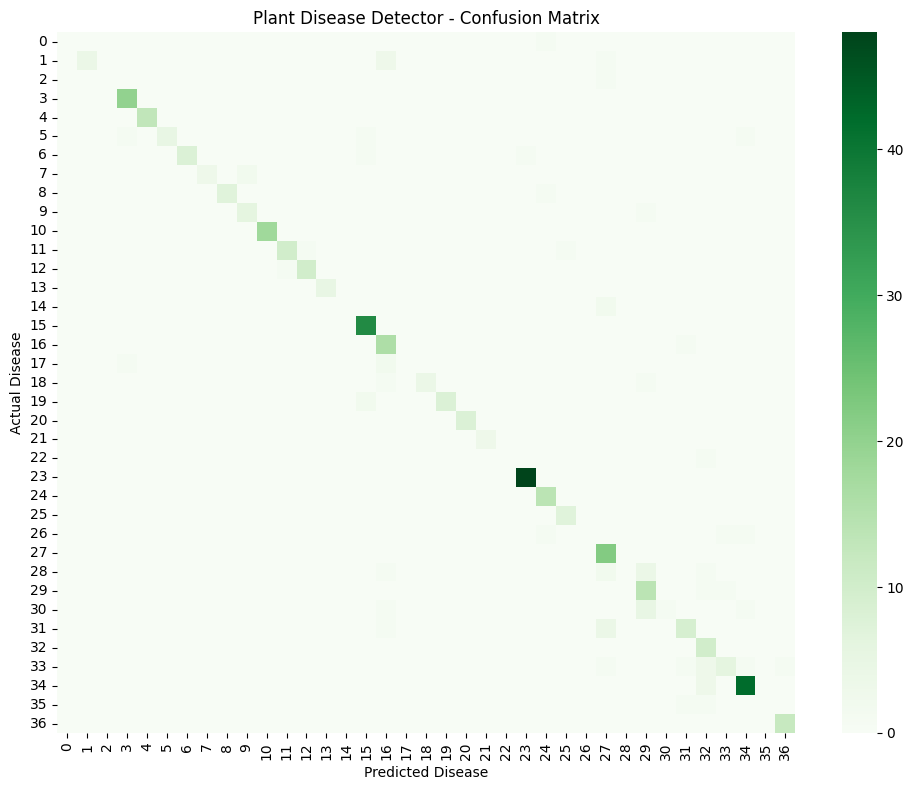

Chart saved as confusion_matrix.png. You can download it from the left file drawer!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

predictions_output = trainer.predict(dataset["test"])
y_preds = np.argmax(predictions_output.predictions, axis=1)
y_true = predictions_output.label_ids

print(f"Final Test Accuracy: {predictions_output.metrics['test_accuracy'] * 100:.2f}%")

# Generate chart
cm = confusion_matrix(y_true, y_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, cmap="Greens")
plt.title("Plant Disease Detector - Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

print("Chart saved as confusion_matrix.png. You can download it from the left file drawer!")

🌿 Actual Class:    Grape___Esca_(Black_Measles)

🤖 AI Predictions:
   Grape___Esca_(Black_Measles): 80.96%
   Grape___Black_rot: 6.35%
   Strawberry___Leaf_scorch: 2.20%
   Tomato___Septoria_leaf_spot: 0.82%
   Squash___Powdery_mildew: 0.78%


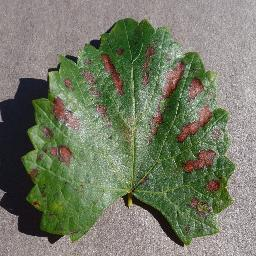

In [ ]:
from transformers import pipeline

# 1. Properly reset formatting to restore raw images
dataset["test"].reset_format()

# 2. Grab a sample test image
sample_test = dataset["test"][0]
test_image = sample_test["image"]
actual_label = labels[sample_test["labels"]]

# 3. Create pipeline using your trained model
classifier = pipeline("image-classification", model=model, image_processor=image_processor)

# 4. Predict
predictions = classifier(test_image)

print(f"🌿 Actual Class:    {actual_label}")
print("\n🤖 AI Predictions:")
for p in predictions:
    print(f"   {p['label']}: {p['score'] * 100:.2f}%")

# 5. Display the photo
display(test_image)

In [ ]:
REPO_NAME = "Humphras-Taylor/plant-disease-model"

print("Uploading 38-class PlantVillage model to Hugging Face...")
model.push_to_hub(REPO_NAME)
image_processor.push_to_hub(REPO_NAME)

print(f"🎉 Done! Your model is now updated with all 38 PlantVillage classes!")

Uploading 38-class PlantVillage model to Hugging Face...


README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...laxfo__/model.safetensors: 100%|##########| 9.26MB / 9.26MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


🎉 Done! Your model is now updated with all 38 PlantVillage classes!
